In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from river import drift

N_DAYS = 100
N_PER_DAY = 200
DRIFT_DAY = 51
LABEL_DELAY = 14
N_SEEDS = 10

DETECTORS = ["ks", "psi", "adwin", "ph"]
SCENARIOS = ["stable", "feature_drift", "concept_drift"]

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True

In [2]:

rng = np.random.default_rng(42)

X_train = rng.normal(size=(5000, 2))

logits = 3 * X_train[:, 0] + 1.5 * X_train[:, 1]
p = 1 / (1 + np.exp(-logits))
y_train = rng.binomial(1, p)

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

reference = X_train[:, 0].copy()

print("Model training accuracy:",
      round(model.score(X_train, y_train), 3))

Model training accuracy: 0.848


In [3]:

def make_psi_edges(reference, n_bins=10):
    edges = np.quantile(
        reference,
        np.linspace(0, 1, n_bins + 1)
    )
    edges[0], edges[-1] = -np.inf, np.inf
    return np.unique(edges)


def calculate_psi(reference, current, edges):
    ref_counts = np.histogram(reference, bins=edges)[0]
    cur_counts = np.histogram(current, bins=edges)[0]

    eps = 1e-6

    p = ref_counts / ref_counts.sum()
    q = cur_counts / cur_counts.sum()

    p = np.maximum(p, eps)
    q = np.maximum(q, eps)

    p = p / p.sum()
    q = q / q.sum()

    return np.sum((q - p) * np.log(q / p))


psi_edges = make_psi_edges(reference)

In [4]:

def generate_data(scenario, seed):
    rng = np.random.default_rng(seed)
    batches = []

    for day in range(1, N_DAYS + 1):
        X = rng.normal(size=(N_PER_DAY, 2))
        beta = 3.0

        if day >= DRIFT_DAY:
            if scenario == "feature_drift":
                X[:, 0] += 1.5

            elif scenario == "concept_drift":
                beta = -3.0

        logits = beta * X[:, 0] + 1.5 * X[:, 1]
        p = 1 / (1 + np.exp(-logits))
        y = rng.binomial(1, p)

        pred = model.predict(X)
        errors = (pred != y).astype(int)

        batches.append({
            "day": day,
            "x1": X[:, 0],
            "errors": errors,
            "accuracy": 1 - errors.mean()
        })

    return batches

In [5]:

def evaluate_run(scenario, seed):

    batches = generate_data(scenario, seed)

    adwin = drift.ADWIN(delta=0.002)
    ph = drift.PageHinkley(
        min_instances=100,
        delta=0.005,
        threshold=30,
        mode="up"
    )

    results = []

    for idx, batch in enumerate(batches):
        day = batch["day"]
        x1 = batch["x1"]

        ks_alert = (
            ks_2samp(reference, x1).pvalue < 0.05
        )

        psi_value = calculate_psi(
            reference, x1, psi_edges
        )
        psi_alert = psi_value > 0.2

        adwin_alert = False
        for value in x1:
            adwin.update(float(value))
            if adwin.drift_detected:
                adwin_alert = True

        # Only process labels that have arrived today
        ph_alert = False
        labeled_idx = idx - LABEL_DELAY

        if labeled_idx >= 0:
            old_errors = batches[labeled_idx]["errors"]

            for error in old_errors:
                ph.update(float(error))
                if ph.drift_detected:
                    ph_alert = True

        results.append({
            "scenario": scenario,
            "seed": seed,
            "day": day,
            "accuracy": batch["accuracy"],
            "ks": bool(ks_alert),
            "psi": bool(psi_alert),
            "adwin": bool(adwin_alert),
            "ph": bool(ph_alert)
        })

    return pd.DataFrame(results)

In [6]:

all_runs = []

for scenario in SCENARIOS:
    for seed in range(N_SEEDS):

        result = evaluate_run(
            scenario=scenario,
            seed=1000 + seed
        )

        all_runs.append(result)

        print(
            f"Completed: {scenario}, seed {seed + 1}"
        )

experiment_df = pd.concat(
    all_runs, ignore_index=True
)

print("\nTotal rows:", len(experiment_df))
print(experiment_df.head())

Completed: stable, seed 1
Completed: stable, seed 2
Completed: stable, seed 3
Completed: stable, seed 4
Completed: stable, seed 5
Completed: stable, seed 6
Completed: stable, seed 7
Completed: stable, seed 8
Completed: stable, seed 9
Completed: stable, seed 10
Completed: feature_drift, seed 1
Completed: feature_drift, seed 2
Completed: feature_drift, seed 3
Completed: feature_drift, seed 4
Completed: feature_drift, seed 5
Completed: feature_drift, seed 6
Completed: feature_drift, seed 7
Completed: feature_drift, seed 8
Completed: feature_drift, seed 9
Completed: feature_drift, seed 10
Completed: concept_drift, seed 1
Completed: concept_drift, seed 2
Completed: concept_drift, seed 3
Completed: concept_drift, seed 4
Completed: concept_drift, seed 5
Completed: concept_drift, seed 6
Completed: concept_drift, seed 7
Completed: concept_drift, seed 8
Completed: concept_drift, seed 9
Completed: concept_drift, seed 10

Total rows: 3000
  scenario  seed  day  accuracy     ks    psi  adwin     ph

In [7]:

def summarize_run(run, detector):
    scenario = run["scenario"].iloc[0]

    if scenario == "stable":
        # Entire simulation is a no-drift control
        false_alerts = int(run[detector].sum())
        false_days = len(run)

        return {
            "scenario": scenario,
            "detector": detector,
            "seed": run["seed"].iloc[0],
            "false_alert_days": false_alerts,
            "false_monitoring_days": false_days,
            "detected": np.nan,
            "delay": np.nan
        }

    pre = run[run["day"] < DRIFT_DAY]

    post = run[
        (run["day"] >= DRIFT_DAY) &
        (run["day"] < DRIFT_DAY + 30)
    ]

    detected_days = post.loc[
        post[detector], "day"
    ]

    detected = len(detected_days) > 0

    return {
        "scenario": scenario,
        "detector": detector,
        "seed": run["seed"].iloc[0],
        "false_alert_days": int(pre[detector].sum()),
        "false_monitoring_days": len(pre),
        "detected": int(detected),
        "delay": (
            int(detected_days.iloc[0] - DRIFT_DAY)
            if detected else np.nan
        )
    }


records = []

for (scenario, seed), run in experiment_df.groupby(
    ["scenario", "seed"]
):
    for detector in DETECTORS:
        records.append(summarize_run(run, detector))

run_summary = pd.DataFrame(records)

comparison = (
    run_summary
    .groupby(["scenario", "detector"])
    .agg(
        total_false_alert_days=("false_alert_days", "sum"),
        total_monitoring_days=("false_monitoring_days", "sum"),
        detection_rate=("detected", "mean"),
        mean_detection_delay=("delay", "mean")
    )
    .reset_index()
)

comparison["false_alert_rate"] = (
    comparison["total_false_alert_days"] /
    comparison["total_monitoring_days"]
)

print(
    comparison[
        ["scenario", "detector",
         "false_alert_rate",
         "detection_rate",
         "mean_detection_delay"]
    ].round(3).to_string(index=False)
)

     scenario detector  false_alert_rate  detection_rate  mean_detection_delay
concept_drift    adwin             0.000             0.0                   NaN
concept_drift       ks             0.056             0.8                   7.5
concept_drift       ph             0.004             1.0                  11.3
concept_drift      psi             0.000             0.0                   NaN
feature_drift    adwin             0.000             1.0                   0.0
feature_drift       ks             0.056             1.0                   0.0
feature_drift       ph             0.004             0.3                   5.0
feature_drift      psi             0.000             1.0                   0.0
       stable    adwin             0.000             NaN                   NaN
       stable       ks             0.055             NaN                   NaN
       stable       ph             0.011             NaN                   NaN
       stable      psi             0.000            

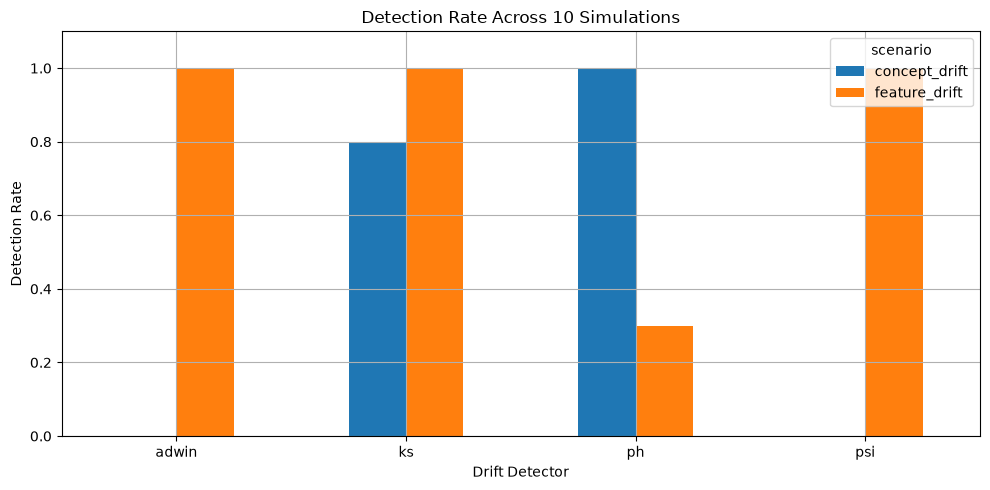

In [8]:

plot_data = comparison[
    comparison["scenario"] != "stable"
]

pivot = plot_data.pivot(
    index="detector",
    columns="scenario",
    values="detection_rate"
)

ax = pivot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Detection Rate Across 10 Simulations")
ax.set_xlabel("Drift Detector")
ax.set_ylabel("Detection Rate")
ax.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

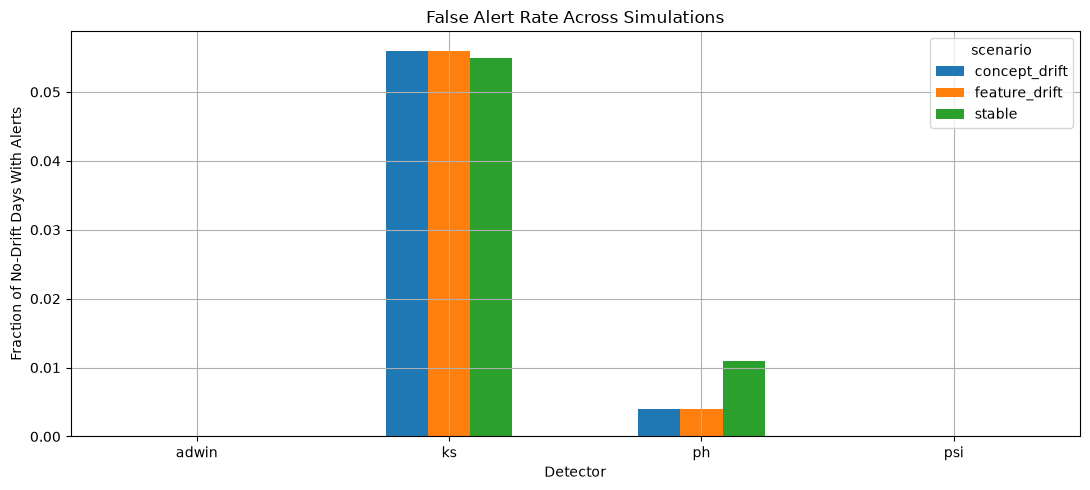

In [9]:

pivot = comparison.pivot(
    index="detector",
    columns="scenario",
    values="false_alert_rate"
)

ax = pivot.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

ax.set_title("False Alert Rate Across Simulations")
ax.set_xlabel("Detector")
ax.set_ylabel("Fraction of No-Drift Days With Alerts")

plt.tight_layout()
plt.show()

In [10]:

from pathlib import Path

# Notebooks execute relative to the VS Code working directory
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

output_dir = project_root / "results"
output_dir.mkdir(exist_ok=True)

comparison.to_csv(
    output_dir / "detector_comparison.csv",
    index=False
)

run_summary.to_csv(
    output_dir / "detector_run_summary.csv",
    index=False
)

print("Results saved to:", output_dir)

Results saved to: c:\Users\khush\drift-research\results


In [11]:

def summarize_corrected(run, detector):
    scenario = run["scenario"].iloc[0]

    # Label-based detector cannot observe changed labels
    # until 14 days after the actual drift.
    earliest_day = (
        DRIFT_DAY + LABEL_DELAY
        if detector == "ph"
        else DRIFT_DAY
    )

    # Same evaluation end for all detectors
    end_day = DRIFT_DAY + 29

    window = run[
        (run["day"] >= earliest_day) &
        (run["day"] <= end_day)
    ]

    alert_days = window.loc[
        window[detector], "day"
    ]

    return {
        "scenario": scenario,
        "seed": run["seed"].iloc[0],
        "detector": detector,
        "eligible_days": len(window),
        "detected": int(len(alert_days) > 0),
        "first_alert_day": (
            int(alert_days.iloc[0])
            if len(alert_days) else np.nan
        ),
        "delay_from_drift": (
            int(alert_days.iloc[0] - DRIFT_DAY)
            if len(alert_days) else np.nan
        )
    }


corrected_records = []

for (scenario, seed), run in experiment_df.groupby(
    ["scenario", "seed"]
):
    for detector in DETECTORS:
        corrected_records.append(
            summarize_corrected(run, detector)
        )

corrected = pd.DataFrame(corrected_records)

In [12]:

corrected_summary = (
    corrected.groupby(["scenario", "detector"])
    .agg(
        alert_probability=("detected", "mean"),
        mean_delay=("delay_from_drift", "mean"),
        eligible_days=("eligible_days", "first")
    )
    .reset_index()
)

null_rates = corrected_summary[
    corrected_summary["scenario"] == "stable"
][["detector", "alert_probability"]].rename(
    columns={
        "alert_probability": "null_alert_probability"
    }
)

corrected_summary = corrected_summary.merge(
    null_rates,
    on="detector",
    how="left"
)

corrected_summary["lift_over_null"] = (
    corrected_summary["alert_probability"] -
    corrected_summary["null_alert_probability"]
)

print(corrected_summary.round(3).to_string(index=False))

     scenario detector  alert_probability  mean_delay  eligible_days  null_alert_probability  lift_over_null
concept_drift    adwin                0.0         NaN             30                     0.0             0.0
concept_drift       ks                0.8         7.5             30                     0.8             0.0
concept_drift       ph                1.0        14.0             16                     0.3             0.7
concept_drift      psi                0.0         NaN             30                     0.0             0.0
feature_drift    adwin                1.0         0.0             30                     0.0             1.0
feature_drift       ks                1.0         0.0             30                     0.8             0.2
feature_drift       ph                0.0         NaN             16                     0.3            -0.3
feature_drift      psi                1.0         0.0             30                     0.0             1.0
       stable    ad

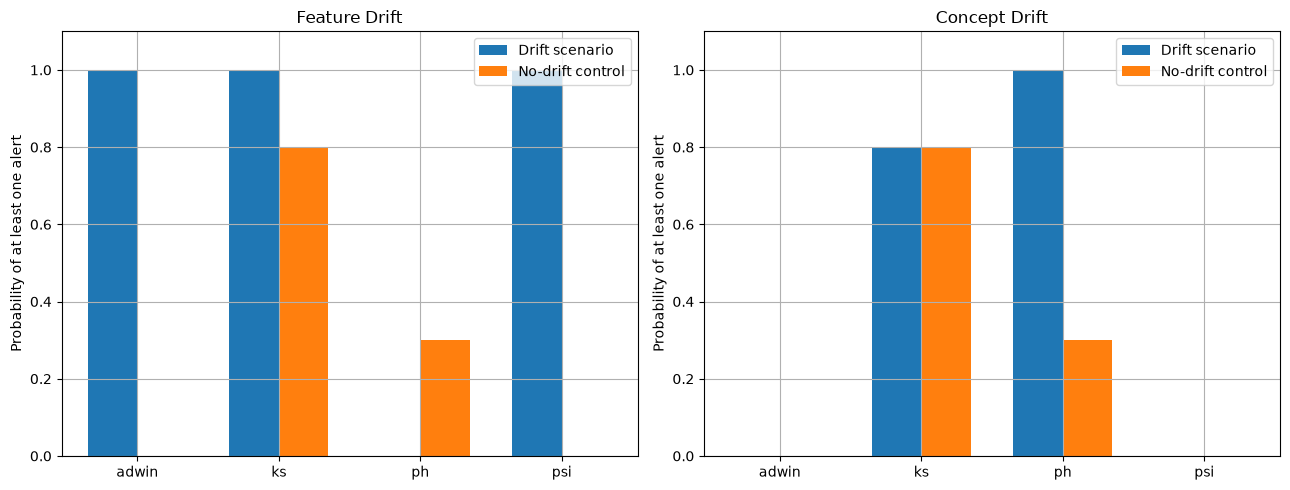

In [13]:

plot_df = corrected_summary[
    corrected_summary["scenario"] != "stable"
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, scenario in zip(
    axes, ["feature_drift", "concept_drift"]
):
    subset = plot_df[
        plot_df["scenario"] == scenario
    ].set_index("detector")

    x = np.arange(len(subset))
    width = 0.35

    ax.bar(
        x - width / 2,
        subset["alert_probability"],
        width,
        label="Drift scenario"
    )

    ax.bar(
        x + width / 2,
        subset["null_alert_probability"],
        width,
        label="No-drift control"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(subset.index)
    ax.set_ylim(0, 1.1)
    ax.set_title(scenario.replace("_", " ").title())
    ax.set_ylabel("Probability of at least one alert")
    ax.legend()

plt.tight_layout()
plt.show()